**Assignment 1: Data Profiling (EDA) Report**

Dataset: Diabetes 130-US Hospitals (1999–2008)

**Group Members:**
- Name: Nur Nadiah Binti Mohd Rizwan (A216675)
- Name: Aisyah Adriana Binti Ahmad Nazri (A216696)
- Name: Syasya Nabilah Binti Fadzil Azhar (A216839)

**1. Scenario**

This project focuses on profiling hospital admission records of patients with diabetes. The dataset contains missing values, possible outliers, and data quality issues that may affect the reliability of healthcare analysis. The main goal is to identify these issues, apply suitable cleaning methods, and assess whether the dataset is suitable for studying hospital readmission patterns.

**2. Data Source**

The dataset was obtained from the Diabetes 130-US Hospitals dataset, which contains hospital encounter records collected between 1999 and 2008. The original dataset contains 101,766 records and 50 attributes. For this assignment, 5,000 records were selected using reproducible random sampling.

The dataset is associated with the research conducted by Strack et al. (2014), which examined the relationship between HbA1c measurement and hospital readmission rates.

**Dataset Source:** https://www.kaggle.com/datasets/brandao/diabetes

**Research Paper:** Strack, B., et al. (2014). *Impact of HbA1c Measurement on Hospital Readmission Rates: Analysis of 70,000 Clinical Database Patient Records*. BioMed Research International. https://doi.org/10.1155/2014/781670

**Method of Data Collection:** The CSV file was downloaded from the open dataset source and uploaded into Google Colab for data profiling.

**Dataset Selection:** This dataset was selected because it contains missing values, possible outliers, and other data quality issues. It is different from the dataset used for the capstone project.

**PART B — LOAD DATASET AND SELECT 5,000 ROWS**

**Import libraries**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

# Display decimal values without scientific notation
pd.set_option("display.float_format", "{:.2f}".format)

print("Libraries imported successfully!")

Libraries imported successfully!


**Check CSV file**

In [ ]:
# Define CSV file path
file_path = Path("diabetic_data.csv")

# Check whether the dataset exists
print("File exists:", file_path.exists())

if file_path.exists():
    print(
        "File size (MB):",
        round(file_path.stat().st_size / 1024**2, 2)
    )
else:
    raise FileNotFoundError(
        "diabetic_data.csv not found. "
        "Place the CSV file in the notebook's working directory."
    )

File exists: True
File size (MB): 3.0


**Check CSV formatting**

In [ ]:
import csv
from collections import Counter

field_counts = Counter()
bad_rows = []

with open(file_path, "r", encoding="utf-8-sig", newline="") as f:
    reader = csv.reader(f)
    header = next(reader)
    expected = len(header)

    for row_number, row in enumerate(reader, start=2):
        field_counts[len(row)] += 1

        if len(row) != expected:
            bad_rows.append({
                "Row": row_number,
                "Fields": len(row)
            })

print("Expected columns:", expected)
print("Field counts:", field_counts)
print("Malformed rows:", len(bad_rows))
display(pd.DataFrame(bad_rows).head())

Expected columns: 50
Field counts: Counter({50: 33242, 10: 1})
Malformed rows: 1


,Row,Fields
0,33244,10


**Load dataset and select exactly 5,000 rows**

In [ ]:
# Read original dataset while preserving "None" categories
df_full = pd.read_csv(
    file_path,
    dtype={
        "encounter_id": "string",
        "patient_nbr": "string"
    },
    keep_default_na=False,
    na_values=["?"],
    low_memory=False
)

print("Original Dataset Shape:", df_full.shape)

# Select exactly 5,000 records
df_raw = df_full.sample(
    n=5000,
    random_state=42
).reset_index(drop=True)

# Save sampled dataset
df_raw.to_csv(
    "diabetic_data_5000.csv",
    index=False
)

print("Selected Dataset Shape:", df_raw.shape)

display(df_raw.head())

Original Dataset Shape: (49655, 50)
Selected Dataset Shape: (5000, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,25604634,8042103,Caucasian,Female,[60-70),NaN,1,1,7,11,...,No,Up,No,No,No,No,No,Ch,Yes,NO
1,4965444,97125948,Caucasian,Male,[60-70),NaN,1,1,1,8,...,No,Steady,No,No,No,No,No,No,Yes,<30
2,47483772,205803,Hispanic,Female,[60-70),NaN,1,18,7,2,...,No,No,No,No,No,No,No,No,Yes,>30
3,91318374,2496051,Caucasian,Male,[60-70),NaN,2,3,1,4,...,No,No,No,No,No,No,No,Ch,Yes,<30
4,56000970,20296278,Caucasian,Male,[0-10),NaN,1,5,7,1,...,No,Down,No,No,No,No,No,Ch,Yes,NO


**Verify IDs and sample**

In [ ]:
print("Total Rows:", len(df_raw))
print("Total Columns:", len(df_raw.columns))

display(
    df_raw[["encounter_id", "patient_nbr"]].head(10)
)

assert len(df_raw) == 5000
assert df_raw.shape[1] == 50

Total Rows: 5000
Total Columns: 50


,encounter_id,patient_nbr
0,25604634,8042103
1,4965444,97125948
2,47483772,205803
3,91318374,2496051
4,56000970,20296278
5,61646160,76986
6,108288630,24737823
7,101036634,111055230
8,97019586,23194098
9,27662190,11982978


**Sampling Method**

Simple random sampling was used to select 5,000 hospital encounters from the original dataset. The random seed was set to 42 to ensure that the same records are selected whenever the code is executed. This approach makes the dataset easier to manage while preserving a random selection of records. However, the sample may still contain imbalanced demographic groups.

**DATA PROFILING AND MISSING VALUES**

**Check dataset information**

In [ ]:
# Create working copy
df = df_raw.copy()

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
display(df.dtypes.to_frame("Data Type"))

print("\nFirst 5 Records:")
display(df.head())

print("\nNumerical Summary:")
display(df.describe())

Dataset Shape: (5000, 50)

Column Names:
['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']

Data Types:


,Data Type
encounter_id,string[python]
patient_nbr,string[python]
race,object
gender,object
age,object
weight,object
admission_type_id,int64
discharge_disposition_id,int64
admission_source_id,int64
time_in_hospital,int64



First 5 Records:


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,25604634,8042103,Caucasian,Female,[60-70),NaN,1,1,7,11,...,No,Up,No,No,No,No,No,Ch,Yes,NO
1,4965444,97125948,Caucasian,Male,[60-70),NaN,1,1,1,8,...,No,Steady,No,No,No,No,No,No,Yes,<30
2,47483772,205803,Hispanic,Female,[60-70),NaN,1,18,7,2,...,No,No,No,No,No,No,No,No,Yes,>30
3,91318374,2496051,Caucasian,Male,[60-70),NaN,2,3,1,4,...,No,No,No,No,No,No,No,Ch,Yes,<30
4,56000970,20296278,Caucasian,Male,[0-10),NaN,1,5,7,1,...,No,Down,No,No,No,No,No,Ch,Yes,NO



Numerical Summary:


,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital
count,5000.00,5000.00,5000.00,5000.00
mean,2.24,4.19,6.30,4.52
std,1.63,5.92,4.75,3.12
min,1.00,1.00,1.00,1.00
25%,1.00,1.00,1.00,2.00
50%,2.00,1.00,7.00,4.00
75%,3.00,5.00,7.00,6.00
max,8.00,28.00,20.00,14.00


**Identify missing values**

In [ ]:
# Replace missing markers
df = df.replace("?", np.nan)

# Calculate missing values
missing_report = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage (%)": (
        df.isna().mean() * 100
    ).round(2)
})

missing_report = missing_report[
    missing_report["Missing Count"] > 0
].sort_values(
    "Missing Percentage (%)",
    ascending=False
)

display(missing_report)

,Missing Count,Missing Percentage (%)
weight,4827,96.54
payer_code,3246,64.92
medical_specialty,1818,36.36
race,144,2.88
diag_3,113,2.26
diag_2,31,0.62
diag_1,1,0.02


**Chart 1: Missing Values**

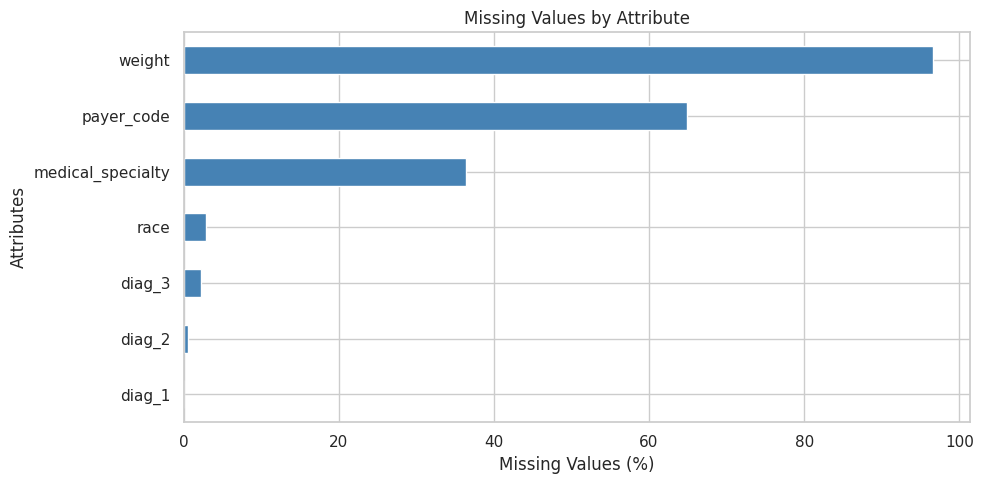

In [ ]:
plt.figure(figsize=(10, 5))

missing_report["Missing Percentage (%)"].sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title("Missing Values by Attribute")
plt.xlabel("Missing Values (%)")
plt.ylabel("Attributes")

plt.tight_layout()
plt.show()

**Chart 1 Interpretation**

The chart shows that several attributes have a lot of missing values, especially weight, medical_specialty, and payer_code. This could affect the reliability of the dataset, so these missing values need to be handled before moving on to further analysis.

**Handle missing values**

In [ ]:
# Create a copy of the original dataset
df_clean = df.copy()

# Attributes with missing values
missing_columns = [
    "race",
    "weight",
    "payer_code",
    "medical_specialty",
    "diag_1",
    "diag_2",
    "diag_3"
]

# Create missing indicators before filling missing values
for col in missing_columns:
    df_clean[f"{col}_missing"] = df_clean[col].isna()

# Replace missing values with Unknown
for col in missing_columns:
    df_clean[col] = df_clean[col].fillna("Unknown")

# Preserve existing None categories for laboratory tests
lab_columns = [
    "max_glu_serum",
    "A1Cresult"
]

for col in lab_columns:
    df_clean[col] = df_clean[col].fillna("Unknown")

# Check remaining missing values
print("Remaining Missing Values:")
display(df_clean.isna().sum()[df_clean.isna().sum() > 0])

# Display missing indicators
print("\nMissing Value Indicators:")
display(df_clean[[f"{col}_missing" for col in missing_columns]].sum())

Remaining Missing Values:


,0



Missing Value Indicators:


,0
race_missing,144
weight_missing,4827
payer_code_missing,3246
medical_specialty_missing,1818
diag_1_missing,1
diag_2_missing,31
diag_3_missing,113


**Missing Values Interpretation**

The dataset contains missing values in several attributes, including race, weight, payer_code, medical_specialty, diag_1, diag_2, and diag_3. Missing values in these attributes were replaced with "Unknown" to retain the records without assigning incorrect information.

Additional missing indicator attributes were created for each affected column to identify records that originally contained missing values. These indicators contain True for missing entries and False for non-missing entries.

The existing "None" categories in max_glu_serum and A1Cresult were preserved because they indicate that the laboratory tests were not performed rather than missing information.

Although the missing values have been handled, the original information cannot be recovered. The missing indicators help preserve information about the dataset's initial missing values.

**Compare missing values before and after cleaning**

In [ ]:

# Compare missing values before and after cleaning
all_columns = df.columns.union(df_clean.columns)

comparison = pd.DataFrame(index=all_columns)

comparison["Before Cleaning"] = (
    df.isna().sum().reindex(all_columns, fill_value=0)
)

comparison["After Cleaning"] = (
    df_clean.isna().sum().reindex(all_columns, fill_value=0)
)

# Identify retained, added, or dropped attributes
comparison["Status"] = [
    "Added" if col not in df.columns
    else "Dropped" if col not in df_clean.columns
    else "Retained"
    for col in comparison.index
]

# Display original attributes and new missing indicators
selected_attributes = [
    "race",
    "race_missing",
    "weight",
    "weight_missing",
    "payer_code",
    "payer_code_missing",
    "medical_specialty",
    "medical_specialty_missing",
    "diag_1",
    "diag_1_missing",
    "diag_2",
    "diag_2_missing",
    "diag_3",
    "diag_3_missing",
    "max_glu_serum",
    "A1Cresult"
]

display(comparison.loc[selected_attributes])


,Before Cleaning,After Cleaning,Status
race,144,0,Retained
race_missing,0,0,Added
weight,4827,0,Retained
weight_missing,0,0,Added
payer_code,3246,0,Retained
payer_code_missing,0,0,Added
medical_specialty,1818,0,Retained
medical_specialty_missing,0,0,Added
diag_1,1,0,Retained
diag_1_missing,0,0,Added


**Chart 2: Missing Values Before vs After**

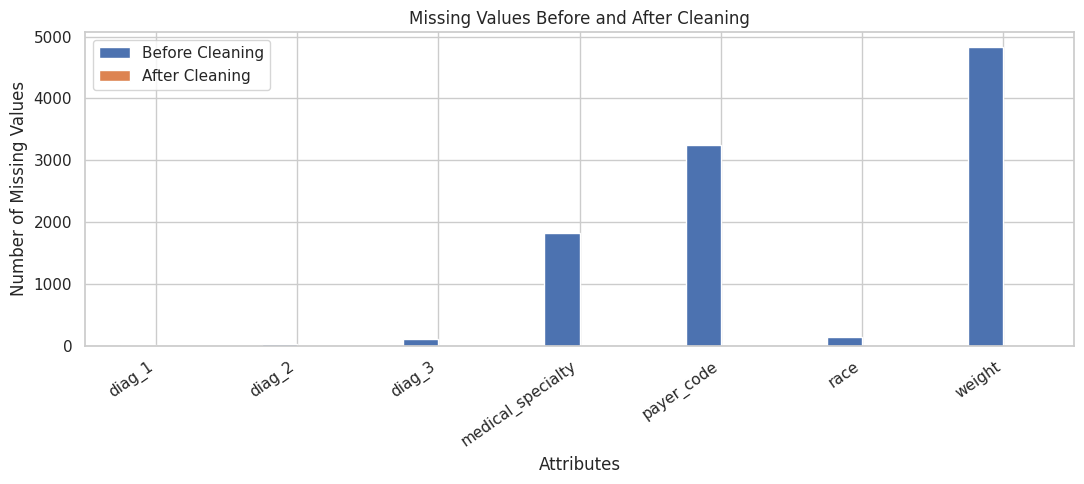

In [ ]:
plot_data = comparison[
    comparison["Before Cleaning"] > 0
][["Before Cleaning", "After Cleaning"]]

plot_data.plot(
    kind="bar",
    figsize=(11, 5)
)

plt.title("Missing Values Before and After Cleaning")
plt.xlabel("Attributes")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=35, ha="right")

plt.tight_layout()
plt.show()

**Chart 2 Interpretation**

The chart shows that missing values were successfully handled during the data cleaning process. Missing values in race, weight, payer_code, medical_specialty, diag_1, diag_2, and diag_3 were replaced with "Unknown".

Seven missing indicator attributes were created to preserve information about the original missing values. These indicators identify which records originally contained missing information.

The existing "None" categories in max_glu_serum and A1Cresult were preserved because they indicate laboratory tests that were not performed.

After cleaning, these attributes no longer have missing values. However, replacing them with "Unknown" does not mean the original information has been recovered.

**OUTLIER DETECTION AND HANDLING**

**Identify numerical attributes**

In [ ]:
numeric_columns = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

display(df_clean[numeric_columns].describe())

,time_in_hospital
count,5000.00
mean,4.52
std,3.12
min,1.00
25%,2.00
50%,4.00
75%,6.00
max,14.00


**Check and Convert Numeric Data Types**

In [ ]:
# Check numerical data types before outlier detection

print("Data Types Before Conversion:")
display(df_clean[numeric_columns].dtypes.to_frame("Data Type"))

# Save original numeric values for comparison
numeric_before = df_clean[numeric_columns].copy()

# Convert numerical columns to numeric types
for col in numeric_columns:
    df_clean[col] = pd.to_numeric(
        df_clean[col],
        errors="coerce"
    )

# Compare missing values before and after conversion
conversion_report = pd.DataFrame({
    "Missing Before": numeric_before.isna().sum(),
    "Missing After": df_clean[numeric_columns].isna().sum()
})

conversion_report["New Missing"] = (
    conversion_report["Missing After"] -
    conversion_report["Missing Before"]
)

print("\nNumeric Conversion Report:")
display(conversion_report)

print("Total New Missing Values:",
      int(conversion_report["New Missing"].sum()))

print("\nData Types After Conversion:")
display(df_clean[numeric_columns].dtypes.to_frame("Data Type"))


Data Types Before Conversion:


,Data Type
time_in_hospital,int64
num_lab_procedures,object
num_procedures,object
num_medications,object
number_outpatient,object
number_emergency,object
number_inpatient,object
number_diagnoses,object



Numeric Conversion Report:


,Missing Before,Missing After,New Missing
time_in_hospital,0,0,0
num_lab_procedures,0,0,0
num_procedures,0,0,0
num_medications,0,0,0
number_outpatient,0,0,0
number_emergency,0,0,0
number_inpatient,0,0,0
number_diagnoses,0,0,0


Total New Missing Values: 0

Data Types After Conversion:


,Data Type
time_in_hospital,int64
num_lab_procedures,int64
num_procedures,int64
num_medications,int64
number_outpatient,int64
number_emergency,int64
number_inpatient,int64
number_diagnoses,int64


**Detect outliers using IQR**

In [ ]:
outlier_results = []

for col in numeric_columns:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)

    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = (
        (df_clean[col] < lower) |
        (df_clean[col] > upper)
    )

    outlier_results.append({
        "Attribute": col,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Outlier Count": int(outliers.sum()),
        "Outlier Percentage (%)": round(
            outliers.mean() * 100, 2
        )
    })

outlier_report = pd.DataFrame(outlier_results)

display(outlier_report)

,Attribute,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage (%)
0,time_in_hospital,-4.00,12.00,140,2.80
1,num_lab_procedures,-9.00,95.00,11,0.22
2,num_procedures,-3.00,5.00,230,4.60
3,num_medications,-3.50,32.50,169,3.38
4,number_outpatient,0.00,0.00,555,11.10
5,number_emergency,0.00,0.00,362,7.24
6,number_inpatient,-1.50,2.50,323,6.46
7,number_diagnoses,-1.00,15.00,0,0.00


**Outlier Detection**

The IQR method was used to identify potential outliers in numerical attributes. High hospital visit counts or medication counts may represent genuine clinical observations rather than data entry errors. Therefore, potential outliers were retained unless they violated defined validation rules. Further clinical verification would be needed to confirm their accuracy.

**Chart 3: Outlier Boxplot**

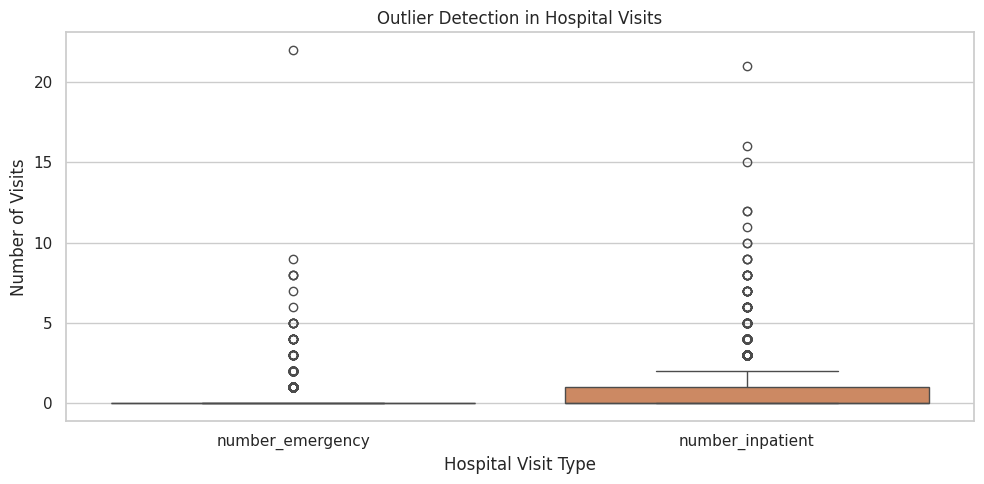

In [ ]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_clean[
        ["number_emergency", "number_inpatient"]
    ]
)

plt.title("Outlier Detection in Hospital Visits")
plt.xlabel("Hospital Visit Type")
plt.ylabel("Number of Visits")

plt.tight_layout()
plt.show()

**Chart 3 Interpretation**

The boxplot highlights unusually high numbers of emergency and inpatient visits. These potential outliers may represent patients with frequent healthcare needs. They are retained unless there is evidence that the values are invalid.

**Handle outliers and invalid numerical values**

In [ ]:
# Handle invalid numerical values

# Check missing or non-convertible numeric values
invalid_numeric_missing = (
    df_clean[numeric_columns].isna().any(axis=1)
)

# Detect negative values
negative_values = (
    df_clean[numeric_columns] < 0
).any(axis=1)

# Check invalid hospital stays
invalid_stay = ~df_clean["time_in_hospital"].between(1, 14)

# Combine all invalid numerical conditions
invalid_rows = (
    invalid_numeric_missing |
    negative_values |
    invalid_stay
)

print("Missing/Non-convertible numeric rows:",
      invalid_numeric_missing.sum())

print("Negative-value rows:",
      negative_values.sum())

print("Invalid hospital-stay rows:",
      invalid_stay.sum())

print("Total invalid rows:",
      invalid_rows.sum())

# Remove only invalid numerical records
before_rows = len(df_clean)

df_clean = df_clean.loc[~invalid_rows].copy()

print("Rows Removed:", before_rows - len(df_clean))
print("Remaining Rows:", len(df_clean))


Missing/Non-convertible numeric rows: 0
Negative-value rows: 0
Invalid hospital-stay rows: 0
Total invalid rows: 0
Rows Removed: 0
Remaining Rows: 5000


**Outlier Handling**

Numerical attributes were converted to appropriate numeric data types before outlier detection. Any non-convertible values were identified as missing values. The IQR method was used to detect potential statistical outliers, which were retained because they may represent genuine hospital encounters rather than data entry errors. However, records containing missing numerical values, negative counts, or hospital stays outside the valid range of 1 to 14 days were removed if detected. This approach preserves meaningful healthcare information while ensuring that invalid numerical records are handled appropriately.

**OTHER DATA QUALITY ISSUES**

**Check duplicates**

In [ ]:
print(
    "Exact Duplicate Rows:",
    df_clean.duplicated().sum()
)

print(
    "Duplicate Encounter IDs:",
    df_clean["encounter_id"].duplicated().sum()
)

print(
    "Repeated Patient IDs:",
    df_clean["patient_nbr"].duplicated().sum()
)

Exact Duplicate Rows: 0
Duplicate Encounter IDs: 0
Repeated Patient IDs: 184


**Handle duplicate encounter records**

In [ ]:
before_rows = len(df_clean)

df_clean = df_clean.drop_duplicates(
    subset="encounter_id",
    keep="first"
).copy()

print("Rows Removed:", before_rows - len(df_clean))
print("Remaining Rows:", len(df_clean))

Rows Removed: 0
Remaining Rows: 5000


**Duplicate Handling**

Duplicate encounter IDs were checked because each hospital encounter should have a unique identifier. Repeated patient IDs were retained because one patient may have multiple legitimate hospital visits. Only duplicate encounter records were removed if found.

**Check inconsistent categories**

In [ ]:
categorical_columns = [
    "gender",
    "race",
    "readmitted",
    "A1Cresult",
    "change",
    "diabetesMed"
]

for col in categorical_columns:
    print(f"\n{col}")
    display(
        df_clean[col].value_counts(dropna=False)
        .to_frame("Count")
    )


gender


,Count
gender,
Female,2736
Male,2264



race


,Count
race,
Caucasian,3582
AfricanAmerican,1115
Unknown,144
Hispanic,89
Other,47
Asian,23



readmitted


,Count
readmitted,
NO,2776
>30,1686
<30,538


... (2 outputs left out)


change


,Count
change,
No,2922
Ch,2078



diabetesMed


,Count
diabetesMed,
Yes,3816
No,1184


**Standardize and validate categories**

In [ ]:

# Standardize invalid gender label
df_clean["gender"] = df_clean["gender"].replace({
    "Unknown/Invalid": "Unknown"
})

# Define valid categories
valid_categories = {
    "gender": {"Male", "Female", "Unknown"},
    "readmitted": {"NO", "<30", ">30"},
    "A1Cresult": {"None", "Norm", ">7", ">8"},
    "change": {"Ch", "No"},
    "diabetesMed": {"Yes", "No"}
}

# Validate categorical values and flag unexpected categories
invalid_category_results = []

for col, allowed in valid_categories.items():

    # Identify values outside allowed categories
    invalid_mask = ~df_clean[col].isin(allowed)

    invalid_count = int(invalid_mask.sum())

    print(f"{col}: {invalid_count} invalid values")

    # Create a flag for unexpected categories
    df_clean[col + "_invalid_flag"] = invalid_mask

    if invalid_count > 0:
        print("Unexpected values:")
        display(
            df_clean.loc[invalid_mask, col]
            .value_counts(dropna=False)
        )

    invalid_category_results.append({
        "Attribute": col,
        "Invalid Count": invalid_count,
        "Handling": (
            "Flagged for review" if invalid_count > 0
            else "No unexpected values"
        )
    })

# Create validation report
invalid_category_report = pd.DataFrame(
    invalid_category_results
)

print("\nInvalid Category Validation Report:")
display(invalid_category_report)

print(
    "Total Invalid Categories:",
    int(invalid_category_report["Invalid Count"].sum())
)

gender: 0 invalid values
readmitted: 0 invalid values
A1Cresult: 0 invalid values
change: 0 invalid values
diabetesMed: 0 invalid values

Invalid Category Validation Report:


,Attribute,Invalid Count,Handling
0,gender,0,No unexpected values
1,readmitted,0,No unexpected values
2,A1Cresult,0,No unexpected values
3,change,0,No unexpected values
4,diabetesMed,0,No unexpected values


Total Invalid Categories: 0


**Check data types**

In [ ]:
# Final Numerical Data Type Validation

# Display numerical attributes and their data types
print("Final Numerical Data Types:")
display(
    df_clean[numeric_columns]
    .dtypes
    .to_frame("Data Type")
)

# Check remaining missing values in numerical attributes
print("\nRemaining Missing Numerical Values:")
display(
    df_clean[numeric_columns]
    .isna()
    .sum()
    .to_frame("Missing Count")
)

# Verify all numerical attributes have valid numeric data types
numeric_validation = all(
    pd.api.types.is_numeric_dtype(df_clean[col])
    for col in numeric_columns
)

print("\nAll numerical columns valid:", numeric_validation)


Final Numerical Data Types:


,Data Type
time_in_hospital,int64
num_lab_procedures,int64
num_procedures,int64
num_medications,int64
number_outpatient,int64
number_emergency,int64
number_inpatient,int64
number_diagnoses,int64



Remaining Missing Numerical Values:


,Missing Count
time_in_hospital,0
num_lab_procedures,0
num_procedures,0
num_medications,0
number_outpatient,0
number_emergency,0
number_inpatient,0
number_diagnoses,0



All numerical columns valid: True


**Data Type and Category Validation**

The numerical attributes were converted into the correct data types before checking for outliers. Invalid numerical values were also checked using the validation rules.

For categorical attributes, the values were checked to make sure they matched the expected categories. One "Unknown/Invalid" gender value was changed to "Unknown" to keep the labels consistent. Other categorical attributes were also checked, and any unexpected values were flagged for further review instead of being replaced directly. This helps avoid incorrect assumptions and keeps the data as accurate as possible.

**PII AND BIAS RISKS**

**Chart 4: Group imbalance**

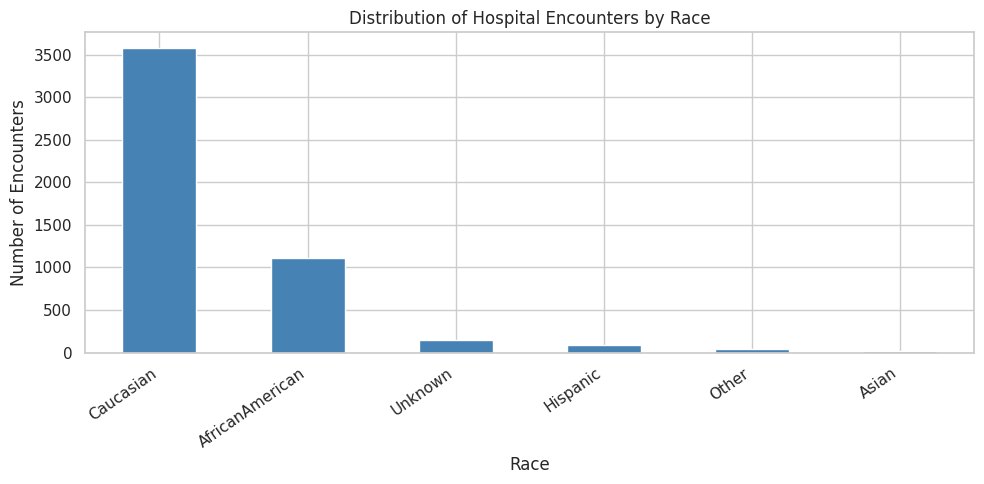

In [ ]:
race_counts = (
    df["race"]
    .fillna("Unknown")
    .value_counts()
)

plt.figure(figsize=(10, 5))

race_counts.plot(kind="bar", color="steelblue")

plt.title("Distribution of Hospital Encounters by Race")
plt.xlabel("Race")
plt.ylabel("Number of Encounters")
plt.xticks(rotation=35, ha="right")

plt.tight_layout()
plt.show()

**Chart 4 Interpretation**

The chart shows that the number of hospital encounters varies across racial groups. Some groups have fewer records than others, which may affect the reliability of comparisons between groups. These differences are important to consider when analyzing the dataset.

**Check demographic balance**

In [ ]:
for col in ["race", "gender", "age", "readmitted"]:

    counts = df[col].fillna("Unknown").value_counts()

    balance = pd.DataFrame({
        "Count": counts,
        "Percentage (%)": (
            counts / len(df) * 100
        ).round(2)
    })

    print(f"\nDistribution: {col}")
    display(balance)


Distribution: race


,Count,Percentage (%)
race,,
Caucasian,3582,71.64
AfricanAmerican,1115,22.30
Unknown,144,2.88
Hispanic,89,1.78
Other,47,0.94
Asian,23,0.46



Distribution: gender


,Count,Percentage (%)
gender,,
Female,2736,54.72
Male,2264,45.28



Distribution: age


,Count,Percentage (%)
age,,
[70-80),1302,26.04
[60-70),1161,23.22
[50-60),860,17.20
[80-90),727,14.54
[40-50),473,9.46
[30-40),211,4.22
[90-100),121,2.42
[20-30),88,1.76
[10-20),42,0.84



Distribution: readmitted


,Count,Percentage (%)
readmitted,,
NO,2776,55.52
>30,1686,33.72
<30,538,10.76


**Compare sample with original dataset**

In [ ]:
original_pct = (
    df_full["readmitted"]
    .value_counts(normalize=True)
    .mul(100)
)

sample_pct = (
    df_raw["readmitted"]
    .value_counts(normalize=True)
    .mul(100)
)

sampling_comparison = pd.DataFrame({
    "Original (%)": original_pct,
    "Sample (%)": sample_pct
}).round(2)

sampling_comparison["Difference (pp)"] = (
    sampling_comparison["Sample (%)"] -
    sampling_comparison["Original (%)"]
).round(2)

display(sampling_comparison)

,Original (%),Sample (%),Difference (pp)
readmitted,,,
,0.00,NaN,NaN
<30,11.47,10.76,-0.71
>30,34.59,33.72,-0.87
NO,53.94,55.52,1.58


**Sampling Representativeness**

The readmission distribution of the 5,000-record sample was compared with the original dataset. Differences in category percentages help assess whether the sample reasonably reflects the original population. However, similarity in readmission distribution alone does not guarantee representativeness across all demographic groups.

**4. PII and Bias Risks**

**4.1 Sensitive Information**

The dataset contains patient IDs, demographic details, diagnosis codes, and medication records. Even though the data has been de-identified, there may still be privacy risks when different attributes are combined.

**Mitigation:** Patient and encounter identifiers will be removed from the final analysis-ready dataset. Results should be reported in aggregated form, and individual patient records should not be publicly disclosed.

**4.2 Sampling Bias**

The dataset contains historical hospital records from the United States between 1999 and 2008. These records may not represent current healthcare practices or patients in other countries.

**Mitigation:** Random sampling with a fixed seed was used to select 5,000 records. The sample distribution was compared with the original dataset to assess representativeness. Findings should not be generalized beyond the population represented by the source.

**4.3 Unbalanced Groups**

The dataset may contain unequal numbers of encounters across race, gender, and age groups. Smaller groups may produce less reliable comparisons.

**Mitigation:** The number and percentage of records in each group were checked to identify any imbalance. Missing demographic values were kept as "Unknown" instead of being guessed. Results involving smaller groups should also be interpreted carefully.

**FINAL CLEANING AND EXPORT**

**Remove sensitive identifiers**

In [ ]:
# Create final cleaned dataset
df_final = df_clean.copy()

# Remove sensitive identifiers
df_final = df_final.drop(
    columns=["encounter_id", "patient_nbr"],
    errors="ignore"
)

# Check final dataset
print("Final Dataset Shape:", df_final.shape)
print("Remaining Missing Values:", df_final.isna().sum().sum())

# Validate final dataset
assert len(df_final) <= 5000
assert "encounter_id" not in df_final.columns
assert "patient_nbr" not in df_final.columns

print("Final dataset validation passed!")

# Display final dataset
display(df_final.head())

Final Dataset Shape: (5000, 60)
Remaining Missing Values: 0
Final dataset validation passed!


,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,...,payer_code_missing,medical_specialty_missing,diag_1_missing,diag_2_missing,diag_3_missing,gender_invalid_flag,readmitted_invalid_flag,A1Cresult_invalid_flag,change_invalid_flag,diabetesMed_invalid_flag
0,Caucasian,Female,[60-70),Unknown,1,1,7,11,Unknown,Unknown,...,True,True,False,False,False,False,False,False,False,False
1,Caucasian,Male,[60-70),Unknown,1,1,1,8,Unknown,Family/GeneralPractice,...,True,False,False,False,False,False,False,False,False,False
2,Hispanic,Female,[60-70),Unknown,1,18,7,2,Unknown,Unknown,...,True,True,False,False,False,False,False,False,False,False
3,Caucasian,Male,[60-70),Unknown,2,3,1,4,Unknown,Podiatry,...,True,False,False,False,False,False,False,False,False,False
4,Caucasian,Male,[0-10),Unknown,1,5,7,1,Unknown,Unknown,...,True,True,False,True,True,False,False,False,False,False


**Final Data Quality Summary**

In [ ]:
summary = pd.DataFrame({
    "Metric": [
        "Original Dataset Rows",
        "Selected Sample Rows",
        "Final Cleaned Rows",
        "Original Columns",
        "Final Columns",
        "Missing Cells Before Cleaning",
        "Missing Cells After Cleaning",
        "Total Outlier Flags"
    ],
    "Result": [
        len(df_full),
        len(df_raw),
        len(df_final),
        df_raw.shape[1],
        df_final.shape[1],
        int(df.isna().sum().sum()),
        int(df_final.isna().sum().sum()),
        int(outlier_report["Outlier Count"].sum())
    ]
})

display(summary)

,Metric,Result
0,Original Dataset Rows,49655
1,Selected Sample Rows,5000
2,Final Cleaned Rows,5000
3,Original Columns,50
4,Final Columns,60
5,Missing Cells Before Cleaning,10180
6,Missing Cells After Cleaning,0
7,Total Outlier Flags,1790


**Export cleaned dataset**

In [ ]:
# Export cleaned dataset
df_final.to_csv(
    "diabetic_data_5000_cleaned.csv",
    index=False
)

# Export missing values comparison
comparison.to_csv(
    "missingness_before_after.csv",
    index=True
)

# Export outlier report
outlier_report.to_csv(
    "outlier_report.csv",
    index=False
)

print("All files exported successfully!")


All files exported successfully!


**5. Conclusion**

We have examined data quality issues in a sample of 5,000 hospital encounters from the Diabetes 130-US Hospitals dataset. The profiling process focused on missing values, outliers, duplicate records, invalid values, and categorical inconsistencies.

Several attributes contained missing information, particularly weight, medical_specialty, and payer_code. Missing values were handled using appropriate cleaning methods, while potential outliers were retained when they represented plausible healthcare observations. Duplicate encounter records and invalid numerical values were also checked.

The cleaned dataset is more suitable for basic exploratory analysis of hospital readmission patterns. However, limitations remain, including missing clinical information, possible demographic imbalance, historical data from 1999 to 2008, and the smaller sample size.

Overall, the dataset is suitable for data profiling because it contains realistic data quality problems.